# PDZ Cis Target-Resample Baseline Results

This notebook visualizes outputs from `scripts/run_pdz_target_resample_baseline.py`.

The script uses sorted `aa_seq` variants from `data/cis_from_bruce_azure.tsv`, checks alignment against the NetCDF observed counts, one-hot encodes the peptide variants, and fits one Ridge model per target draw. Results compare models trained on the MLE point estimate, MLE posterior target resamples, and/or HMC posterior target resamples.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
results_dir = project_root / "results" / "pdz_cis_target_resample_baseline"
correlations_path = results_dir / "correlations.csv"
summary_path = results_dir / "summary.csv"

sns.set_theme(style="whitegrid", context="notebook")

print(f"Project root: {project_root}")
print(f"Correlations: {correlations_path}")
print(f"Summary: {summary_path}")

Project root: c:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness
Correlations: c:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness\results\pdz_cis_target_resample_baseline\correlations.csv
Summary: c:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness\results\pdz_cis_target_resample_baseline\summary.csv


In [2]:
if not correlations_path.exists() or not summary_path.exists():
    missing = correlations_path if not correlations_path.exists() else summary_path
    raise FileNotFoundError(
        "Run scripts/run_pdz_target_resample_baseline.py first. "
        f"Missing {missing}."
    )

correlations = pd.read_csv(correlations_path)
summary = pd.read_csv(summary_path)

required_columns = {"resample_source", "target_variable", "spearman", "target_spearman_vs_eval"}
missing_columns = required_columns - set(correlations.columns)
if missing_columns:
    raise ValueError(f"correlations.csv is missing expected columns: {sorted(missing_columns)}")

summary.sort_values("resample_source")

,resample_source,n,mean,median,std,target_spearman_mean
0,hmc,100,0.840863,0.840875,0.001114,0.974393
1,mle,100,0.833193,0.833427,0.001534,0.984541
2,mle_point_estimate,1,0.841412,0.841412,NaN,1.000000


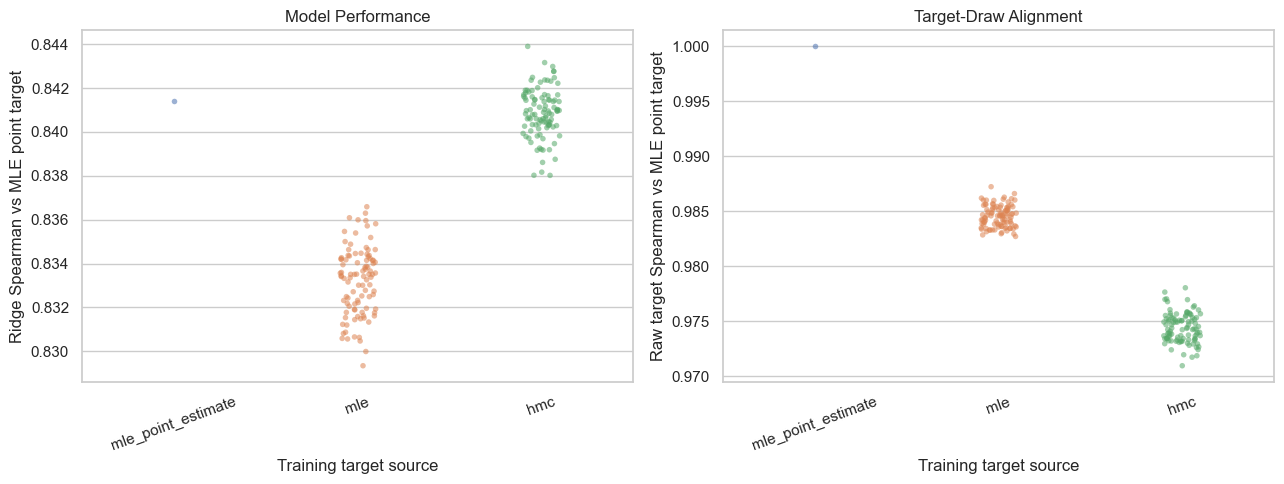

In [3]:
source_order = ["mle_point_estimate", "mle", "hmc"]
plot_data = correlations.copy()
plot_data["resample_source"] = pd.Categorical(
    plot_data["resample_source"],
    categories=[source for source in source_order if source in set(plot_data["resample_source"])],
    ordered=True,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

sns.stripplot(
    data=plot_data,
    x="resample_source",
    y="spearman",
    hue="resample_source",
    order=plot_data["resample_source"].cat.categories,
    palette="deep",
    alpha=0.55,
    size=4,
    legend=False,
    ax=axes[0],
)
axes[0].set_xlabel("Training target source")
axes[0].set_ylabel("Ridge Spearman vs MLE point target")
axes[0].set_title("Model Performance")

sns.stripplot(
    data=plot_data,
    x="resample_source",
    y="target_spearman_vs_eval",
    hue="resample_source",
    order=plot_data["resample_source"].cat.categories,
    palette="deep",
    alpha=0.55,
    size=4,
    legend=False,
    ax=axes[1],
)
axes[1].set_xlabel("Training target source")
axes[1].set_ylabel("Raw target Spearman vs MLE point target")
axes[1].set_title("Target-Draw Alignment")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()